## Calibration of camera

In [2]:
import numpy as np
import cv2
import os
import glob
from matplotlib import pyplot as plt


## Load the calibration images from data/0_calib


37 left, 37 right
data/0_calib/left/000.png <-> data/0_calib/right/000.png


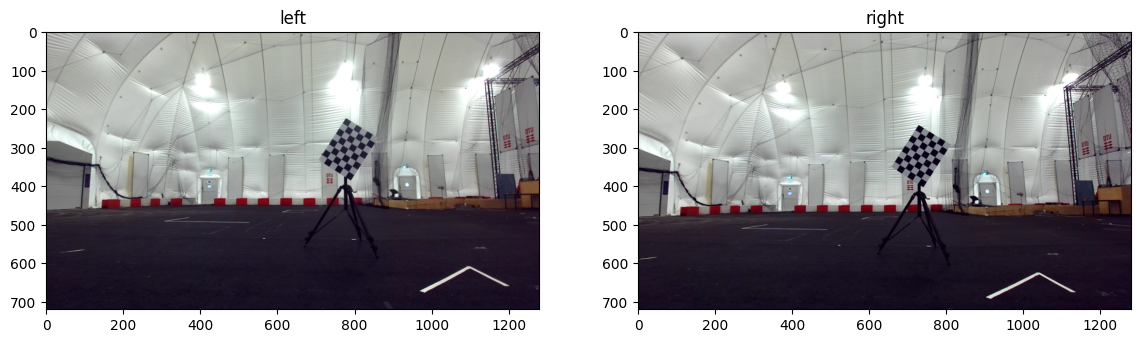

In [3]:
lefts = sorted(glob.glob("data/0_calib/left/0*.png"))
rights = sorted(glob.glob("data/0_calib/right/0*.png"))
print(len(lefts), "left,", len(rights), "right")

# Ensure the left and right images are aligned in the lists
print(lefts[0], "<->", rights[0])

imgL = cv2.imread(lefts[0])
imgR = cv2.imread(rights[0])
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(imgL[..., ::-1]); ax[0].set_title("left")
ax[1].imshow(imgR[..., ::-1]); ax[1].set_title("right")
plt.show()


## Find the horizontal and vertical corners

### From manually counting it should be 7,5

In [4]:
gL = cv2.imread(lefts[0], 0)

# iterate through both axes to find the internal corners, 
# checked by counting the corners manually
for nx in range(4, 12):
    for ny in range(4, 12):
        if ny > nx:
            continue
        ok, _ = cv2.findChessboardCorners(gL, (nx, ny), None)
        if ok:
            print("found:", (nx, ny))

found: (6, 4)


In [5]:


# define the found corners and the square measurement given in the exercise
nb_vertical = 7
nb_horizontal = 5
square = 80.0  # mm


# prepare object points, like (0,0,0), (1,0,0), (2,0,0) ....,(6,5,0)
objp = np.zeros((nb_horizontal*nb_vertical,3), np.float32)
objp[:,:2] = np.mgrid[0:nb_vertical,0:nb_horizontal].T.reshape(-1,2) * square

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)


# Arrays to store object points and image points from all the images. 
# We need 2 imagepoints lists since we are working with two camera
objpoints = [] # 3d point in real world space
imgpointsL = [] # 2d points in image plane left.
imgpointsR = [] # 2d points in image plane right.

imagesL = lefts
imagesR = rights
assert imagesL and len(imagesL) == len(imagesR)
# iterate through the image pairs (left/right) 
for fnameL, fnameR in zip(imagesL, imagesR):
    imgL = cv2.imread(fnameL)
    imgR = cv2.imread(fnameR)

    #convert grayscale, since Chessboard detection only requires intensity information.
    grayL = cv2.cvtColor(imgL, cv2.COLOR_BGR2GRAY)
    grayR = cv2.cvtColor(imgR, cv2.COLOR_BGR2GRAY)

    # for both images we find the corners using the internal corner counts we found earlier, 
    # to check correctness we collect the retL and retR to only add corners that are found on both images
    retL, cornersL = cv2.findChessboardCornersSB(
        grayL, (nb_vertical, nb_horizontal), None
    )
    retR, cornersR = cv2.findChessboardCornersSB(
        grayR, (nb_vertical, nb_horizontal), None
    )

    # Only use this image pair if the chessboard was detected
    # successfully in both the left and right images.
    if retL == True and retR == True:

        # Add the known 3D chessboard coordinates.
        # The same object-point pattern is used for every image pair.
        objpoints.append(objp)

        cl = cornersL.reshape(-1, 2)
        cr = cornersR.reshape(-1, 2)
        if np.dot(cl[-1] - cl[0], cr[-1] - cr[0]) < 0:
            cr = cr[::-1].copy()
        imgpointsL.append(cl.reshape(-1, 1, 2))
        imgpointsR.append(cr.reshape(-1, 1, 2))

        # Draw and display the corners.
        imgL = cv2.drawChessboardCorners(
            imgL, (nb_vertical, nb_horizontal), cornersL, retL
        )
        imgR = cv2.drawChessboardCorners(
            imgR, (nb_vertical, nb_horizontal), cornersR, retR
        )
        cv2.imshow("img", np.hstack((imgL, imgR)))
        cv2.waitKey(150)

cv2.destroyAllWindows()

print(len(objpoints), "of", len(imagesL), "pairs usable")
print(retL, "left,", retR, "right")


25 of 37 pairs usable
True left, True right


In [6]:
print(retL, "left,", retR, "right")


True left, True right


In [ ]:
# Take Image size as (width, height) from one of the image pairs, since they are the same for both cameras
image_size = grayL.shape[::-1]
print("Image size:", image_size)

# Calibrate the left camera
retL, mtxL, distL, rvecsL, tvecsL = cv2.calibrateCamera(objpoints, imgpointsL, image_size, None, None, flags=cv2.CALIB_FIX_K3)
# Calibrate the right camera
retR, mtxR, distR, rvecsR, tvecsR = cv2.calibrateCamera(objpoints, imgpointsR, image_size, None, None, flags=cv2.CALIB_FIX_K3)
print("Left RMS reprojection error:", retL)
print("Right RMS reprojection error:", retR)

print("Left camera matrix:")
print(mtxL)
print("Right camera matrix:")
print(mtxR)

print("Left distortion coefficients:")
print(distL)
print("Right distortion coefficients:")
print(distR)

Image size: (1280, 720)
Left RMS reprojection error: 0.15188658745057518
Right RMS reprojection error: 0.14628411600405525
Left camera matrix:
[[617.16304419   0.         667.75208296]
 [  0.         618.3623206  381.11121508]
 [  0.           0.           1.        ]]
Right camera matrix:
[[615.14180749   0.         648.60068427]
 [  0.         615.97527632 401.86446951]
 [  0.           0.           1.        ]]
Left distortion coefficients:
[[-0.08129552  0.09211793  0.00483495  0.00184786 -0.04915383]]
Right distortion coefficients:
[[-0.07126171  0.06774225  0.00587648  0.0015551  -0.03196212]]


### Undistort Image
Undistort a sample image using the calibration results, and compare it side by side with the original.

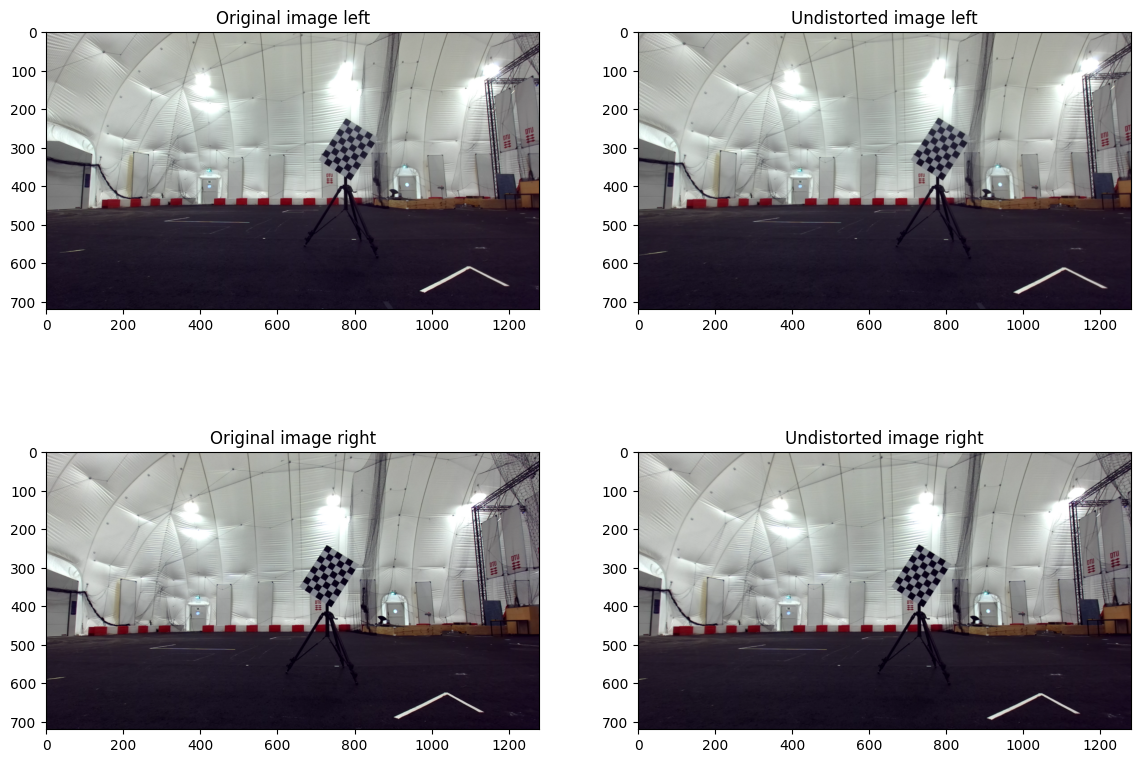

In [8]:
# load first image from pair, both left and right one
imgL = cv2.imread(lefts[0])
imgR = cv2.imread(rights[0])

dstL = cv2.undistort(imgL, mtxL, distL, None, None)
dstR = cv2.undistort(imgR, mtxR, distR, None, None)

# plot the comparisons left to right
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
ax[0,0].imshow(imgL[..., [2, 1, 0]])
ax[0, 0].set_title("Original image left")
ax[0, 1].imshow(dstL[..., [2, 1, 0]])
ax[0, 1].set_title("Undistorted image left")
ax[1, 0].imshow(imgR[..., [2, 1, 0]])
ax[1, 0].set_title("Original image right")
ax[1, 1].imshow(dstR[..., [2, 1, 0]])
ax[1, 1].set_title("Undistorted image right")
plt.show()

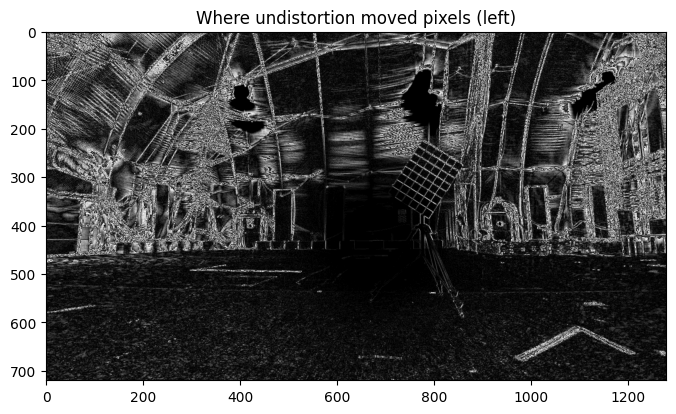

In [9]:
diff = cv2.absdiff(imgL, dstL)
plt.figure(figsize=(8, 6))
plt.imshow(diff[..., 0] * 10, cmap="gray")   # x10 to make small changes visible
plt.title("Where undistortion moved pixels (left)")
plt.show()

## Calibration

In [ ]:
#calibrate

# define flags and criteria from default in opencv documentation
flags = cv2.CALIB_USE_INTRINSIC_GUESS | cv2.CALIB_FIX_K3
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 1e-5) # only adjusted the accuracy threshold from 1e-6 to 1e-5
                                                                           # used AI to adjust the accuracy threshold value to improve results

retS, mtxL, distL, mtxR, distR, R, T, E, F = cv2.stereoCalibrate(
    objpoints, imgpointsL, imgpointsR,
    mtxL, distL, mtxR, distR,
    image_size, criteria=criteria, flags=flags)

print("Stereo RMS reprojection error:", retS)
print("Rotation R (left -> right):")
print(R)
print("Translation T (mm):")
print(T.ravel())
print("Baseline (mm):", np.linalg.norm(T))

Stereo RMS reprojection error: 0.16529049860476397
Rotation R (left -> right):
[[ 9.99969553e-01  8.17418905e-04 -7.76050454e-03]
 [-8.25211776e-04  9.99999158e-01 -1.00102171e-03]
 [ 7.75967976e-03  1.00739529e-03  9.99969386e-01]]
Translation T (mm):
[-119.75639775    0.20936824   -0.79147688]
Baseline (mm): 119.75919619365986


## Rectification

P1 focal: 1180.774048723772  roiL: (0, 0, 1280, 720)
mtxL:
 [[618.10881496   0.         665.68614862]
 [  0.         618.86180202 374.95158229]
 [  0.           0.           1.        ]] 
distL: [-0.07850288  0.08686927  0.00315385  0.00119728 -0.04514295]
baseline: 119.75919619365986
mtxR:
 [[617.27368578   0.         644.94596243]
 [  0.         618.04378718 393.38496496]
 [  0.           0.           1.        ]] 
distR: [-0.07335608  0.07527834  0.00300286  0.00045225 -0.03702555]
R (deg): [ 0.0575375  -0.44462512 -0.04705839]  T: [-119.75639775    0.20936824   -0.79147688]
image_size: (1280, 720)


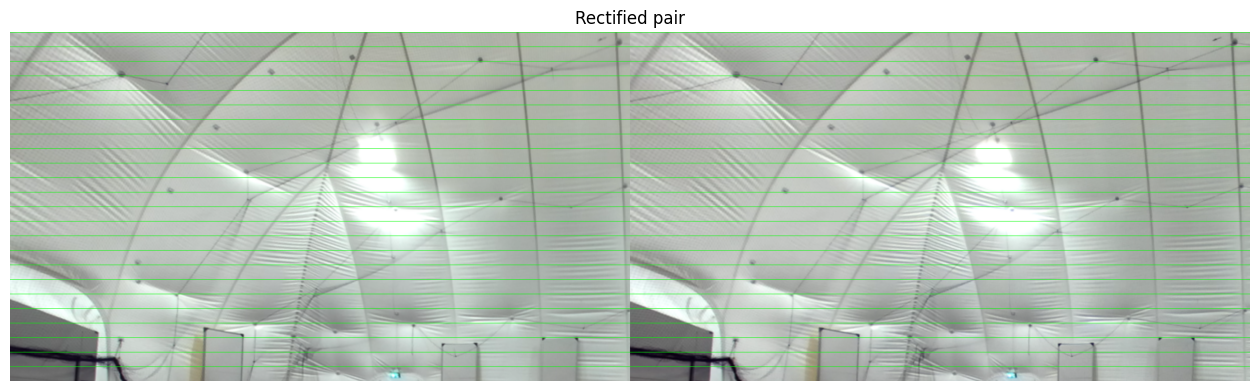

In [11]:
# Compute the rectification transforms
R1, R2, P1, P2, Q, roiL, roiR = cv2.stereoRectify(
    mtxL, distL, mtxR, distR, image_size, R, T, alpha=0)

print("P1 focal:", P1[0, 0], " roiL:", roiL)
print("mtxL:\n", mtxL, "\ndistL:", distL.ravel())
print("baseline:", np.linalg.norm(T))
print("mtxR:\n", mtxR, "\ndistR:", distR.ravel())
print("R (deg):", np.degrees(cv2.Rodrigues(R)[0].ravel()), " T:", T.ravel())
print("image_size:", image_size)

# Build the undistort + rectify maps (only needed once)
mapLx, mapLy = cv2.initUndistortRectifyMap(mtxL, distL, R1, P1, image_size, cv2.CV_32FC1)
mapRx, mapRy = cv2.initUndistortRectifyMap(mtxR, distR, R2, P2, image_size, cv2.CV_32FC1)

# Apply them to one pair
rectL = cv2.remap(imgL, mapLx, mapLy, cv2.INTER_LINEAR)
rectR = cv2.remap(imgR, mapRx, mapRy, cv2.INTER_LINEAR)

# Show side by side with horizontal lines every 30 px
both = np.hstack((rectL, rectR))
for y in range(0, both.shape[0], 30):
    cv2.line(both, (0, y), (both.shape[1], y), (0, 255, 0), 1)

plt.figure(figsize=(16, 6))
plt.imshow(both[..., [2, 1, 0]])
plt.title("Rectified pair")
plt.axis("off")
plt.show()

In [12]:
for i in range(len(objpoints)):
    Rl = cv2.Rodrigues(rvecsL[i])[0]
    Rr = cv2.Rodrigues(rvecsR[i])[0]
    angle = np.degrees(np.linalg.norm(cv2.Rodrigues(Rr @ Rl.T)[0]))
    print(i, round(angle, 1))

0 0.3
1 0.8
2 0.8
3 1.5
4 0.5
5 0.7
6 0.5
7 0.7
8 0.5
9 0.6
10 0.6
11 0.5
12 0.4
13 1.9
14 0.6
15 0.9
16 1.0
17 0.4
18 0.3
19 1.2
20 1.4
21 0.6
22 0.5
23 0.7
24 1.1


In [13]:
#save calibration results:
np.savez("results/stereo_calib.npz",
         mtxL=mtxL, distL=distL, mtxR=mtxR, distR=distR,
         R=R, T=T, R1=R1, R2=R2, P1=P1, P2=P2, Q=Q,
         image_size=np.array(image_size))

In [14]:
gL = cv2.imread("data/1_no_obstacle/left/000000.png", 0)
gR = cv2.imread("data/1_no_obstacle/right/000000.png", 0)
rL = cv2.remap(gL, mapLx, mapLy, cv2.INTER_LINEAR)
rR = cv2.remap(gR, mapRx, mapRy, cv2.INTER_LINEAR)

orb = cv2.ORB_create(2000)
kL, dL = orb.detectAndCompute(rL, None)
kR, dR = orb.detectAndCompute(rR, None)
matches = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True).match(dL, dR)
dy = np.array([abs(kL[m.queryIdx].pt[1] - kR[m.trainIdx].pt[1]) for m in matches])
print("matches:", len(dy), " median row difference (px):", np.median(dy))

matches: 581  median row difference (px): 0.0
